<a href="https://colab.research.google.com/github/JonerciJon/CSST106/blob/main/Lab_Experiment_2_Edge_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Upload your image file (e.g., input.jpg), or cancel to generate a test image:


Saving 2.jpg to 2.jpg


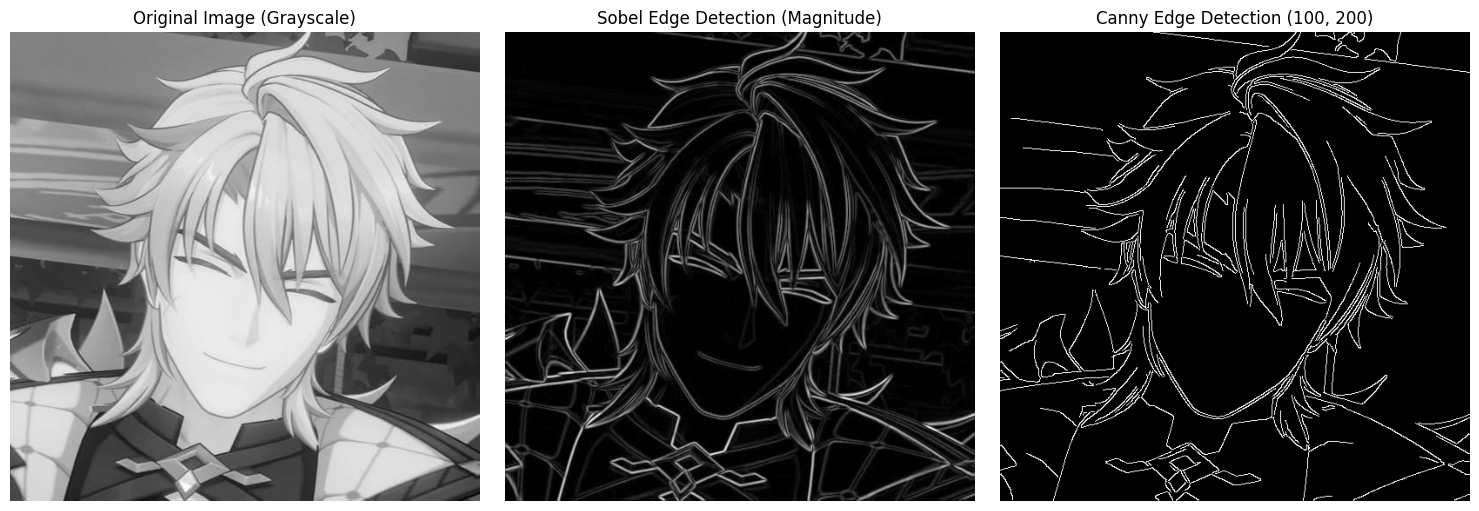

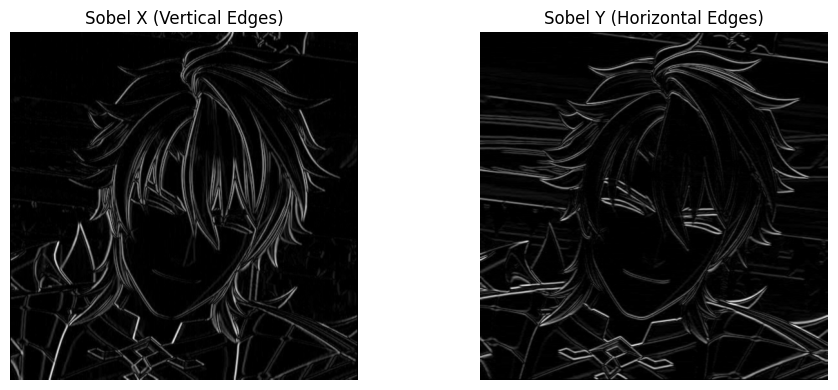

In [1]:
# ==============================================================================
# CSST106 - Laboratory Exercise No. 3: Edge Detection Technique
# Colab-compatible OpenCV script comparing Sobel and Canny edge detectors
# ==============================================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files


def load_or_create_input(target_filename="input.jpg"):
    """Upload an image in Colab (ideally named input.jpg) or create a fallback."""
    print("Upload your image file (e.g., input.jpg), or cancel to generate a test image:")
    try:
        uploaded = files.upload()
        if uploaded:
            first_name = next(iter(uploaded))
            # If the user uploaded a file with another name, also save/read it cleanly
            if first_name != target_filename:
                with open(target_filename, "wb") as f:
                    f.write(uploaded[first_name])
            return target_filename
    except Exception:
        pass

    print("No file uploaded; generating a synthetic sample image saved as 'input.jpg'...")
    synth = np.zeros((360, 540, 3), dtype=np.uint8)
    synth[:, :] = (210, 210, 210)  # Light gray background

    # Distinct shapes and textures to highlight Sobel vs. Canny differences
    cv2.rectangle(synth, (50, 60), (210, 290), (40, 40, 40), thickness=-1)
    cv2.circle(synth, (360, 175), 85, (90, 90, 90), thickness=-1)
    cv2.line(synth, (40, 320), (500, 40), (20, 20, 20), thickness=3)

    # Add slight Gaussian noise to demonstrate blur + thresholding behavior
    rng = np.random.default_rng(42)
    noise = rng.normal(0, 10, synth.shape).astype(np.int16)
    synth = np.clip(synth.astype(np.int16) + noise, 0, 255).astype(np.uint8)

    cv2.imwrite(target_filename, synth)
    return target_filename


def edge_detection(image_path="input.jpg", low_threshold=100, high_threshold=200):
    # 1. Load the image in grayscale
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        print(f"Error: Image '{image_path}' not found or path is incorrect.")
        return

    # 2. Apply Gaussian blur to reduce high-frequency noise before gradient computation
    img_blur = cv2.GaussianBlur(img, (3, 3), 0)

    # 3. Sobel edge detection (gradients along x and y directions)
    # Using CV_64F prevents overflow/underflow on negative gradients
    sobelx = cv2.Sobel(img_blur, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(img_blur, cv2.CV_64F, 0, 1, ksize=3)
    sobel_combined = cv2.magnitude(sobelx, sobely)

    # Normalize combined magnitude to 0-255 uint8 for clean visualization/saving
    sobel_vis = cv2.normalize(sobel_combined, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    # 4. Canny edge detection (gradient + non-maximum suppression + hysteresis thresholding)
    edges_canny = cv2.Canny(img_blur, low_threshold, high_threshold)

    # 5. Side-by-side comparison required by the lab activity
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(img, cmap="gray")
    plt.title("Original Image (Grayscale)")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(sobel_vis, cmap="gray")
    plt.title("Sobel Edge Detection (Magnitude)")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(edges_canny, cmap="gray")
    plt.title(f"Canny Edge Detection ({low_threshold}, {high_threshold})")
    plt.axis("off")

    plt.tight_layout()
    plt.savefig("lab03_sobel_vs_canny.png", dpi=150)
    plt.show()

    # Optional: inspect directional Sobel gradients (Sobel X and Sobel Y)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(np.abs(sobelx), cmap="gray")
    axes[0].set_title("Sobel X (Vertical Edges)")
    axes[0].axis("off")

    axes[1].imshow(np.abs(sobely), cmap="gray")
    axes[1].set_title("Sobel Y (Horizontal Edges)")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    img_file = load_or_create_input("input.jpg")
    edge_detection(img_file, low_threshold=100, high_threshold=200)